# 16S rRNA V4 amplicon profiling with DADA2

**Design:** V4 (515F / 806R) · Illumina MiSeq 2×250 · 1 sequencing run · negative control and/or mock community optional
**Kernel:** R (IRkernel)

> **V4 on 2×250.** The V4 amplicon is ~253 bp between the primers, so 2×250 reads overlap by well over 100 bp. Low-quality read ends can be truncated freely (the default is 240/160, as in the DADA2 tutorial). Merging is rarely the limiting step.
>
> **Primers.** Some V4 protocols put the primers in the reads (e.g. EMP 515F/806R with a separate sequencing primer). Others use the gene primer as the sequencing primer, so the reads start right after it (e.g. Kozich et al. 2013 / the mothur MiSeq SOP). Section 4 detects which case applies and runs cutadapt only if primers are present (`primers_in_reads = NA`, auto).

| Stage | Section | Main output |
|---|---|---|
| 0 | Project parameters | `params` |
| 1 | Environment | package versions |
| 2 | Inputs and sample sheet | validated metadata |
| 3 | Raw read QC | quality profiles |
| 4 | Primer removal (cutadapt) | primer-free FASTQs |
| 5 | Filter and trim | filtered FASTQs |
| 6 | Error model | `errs` |
| 7–8 | Denoise and merge | per-run sequence tables, merge rate |
| 9 | ASV table, chimera removal | `seqtab.nochim` |
| 10 | Read tracking | `read_tracking.tsv` |
| 11 | Taxonomy (SILVA 138.2) | `taxa` |
| 12 | Contaminants and off-target taxa | cleaned table |
| 13 | phyloseq object and export | `phyloseq.rds`, TSV, FASTA |
| 14 | Downstream analysis, **metadata-driven** | diversity, ordination, PERMANOVA, differential abundance |
| 15 | Session record | `sessionInfo.txt` |

## 0. Project parameters
All tunable values live here. Step 14 reads its study variables from the metadata table. Leave `group_vars` / `num_vars` as `NULL` to auto-detect them, or name them explicitly.

In [5]:
params <- list(
  project      = "my_16S_project",              # TODO
  raw_dir      = "data/raw_seq",                # TODO demultiplexed per-sample FASTQs
  out_dir      = "results",
  cache_dir    = "results/cache",
  metadata     = "data/metadata.tsv",           # TODO see section 2 for required columns
  fwd_pattern  = "_R1(_001)?\\.f(ast)?q(\\.gz)?$",   # regex: matches _R1.fastq, _R1_001.fastq.gz, _R1.fq ...
  rev_pattern  = "_R2(_001)?\\.f(ast)?q(\\.gz)?$",
  sample_id_regex = "_.*$",                     # removed from file name to get sample_id: "F3D0_S188_L001_R1_001.fastq" -> "F3D0"

  # Primers: 515F (Parada) / 806R (Apprill). The degenerate versions also match the original EMP/Kozich primers.
  primer_fwd   = "GTGYCAGCMGCCGCGGTAA",        # 515F
  primer_rev   = "GGACTACNVGGGTWTCTAAT",       # 806R
  primers_in_reads = NA,                        # NA = auto-detect in section 4 | TRUE = always cutadapt | FALSE = skip
  amplicon_len = c(250, 256),                   # merged V4 length without primers (most ASVs are 252-254 bp)

  mode         = "paired",                      # "paired" | "forward_only"
  trunc_len    = c(240, 160),                   # TODO adjust from section 3 plots (reverse reads usually degrade first)
  max_ee       = c(2, 2),
  trunc_q      = 2,
  min_overlap  = 12,
  min_merge_rate = 0.5,                         # warn below this fraction of denoised reads merged
  pool         = "pseudo",                      # FALSE | "pseudo" | TRUE
  silva_train  = "refs/silva_nr99_v138.2_toGenus_trainset.fa.gz",
  silva_species= "refs/silva_v138.2_assignSpecies.fa.gz",
  mock_ref     = NULL,                          # optional FASTA of the mock community's true sequences (e.g. "data/raw_seq/HMP_MOCK.v35.fasta")

  decontam_threshold = 0.5,                     # 0.5 = flag ASVs more prevalent in controls than samples
  dna_conc_col = NULL,                          # optional metadata column with DNA conc. -> adds frequency method

  # Step 14
  group_vars   = NULL,                          # NULL = auto-detect categorical columns (2-10 levels)
  num_vars     = NULL,                          # NULL = auto-detect numeric columns
  min_depth    = 5000,                          # samples below this are dropped from downstream analysis
  alpha_level  = 0.05,
  threads      = TRUE,
  seed         = 100
)
dir.create(params$cache_dir, recursive = TRUE, showWarnings = FALSE)
set.seed(params$seed)

### Helpers
The slow steps are cached to `.rds` files, so a kernel restart doesn't recompute them. Each cache file name includes a fingerprint of the input files and every parameter that affects that step and the steps before it. Changing a setting therefore re-runs the affected steps automatically, and an old cache is never reused by mistake.

In [6]:
cached <- function(name, expr, key) {
  f <- file.path(params$cache_dir, paste0(name, "_", substr(rlang::hash(key), 1, 10), ".rds"))
  if (file.exists(f)) { message("loading cached: ", name); return(readRDS(f)) }
  val <- eval.parent(substitute(expr))
  saveRDS(val, f); val
}
getN <- function(x) sum(dada2::getUniques(x))

## 1. Environment
Build from the accompanying `environment.yml`:
```
mamba env create -f environment.yml
conda activate dada2-16s
R -e 'IRkernel::installspec(name = "dada2-16s", displayname = "R (dada2-16s)")'
```
It contains three compatibility pins found while testing: `tbb=2020.2` (otherwise dada2 fails to load), `r-cvxr<1.9` (otherwise ANCOMBC fails to load), and `r-lme4>=1.1.36` plus `r-reformulas` (otherwise the CVXR pin pulls in an incompatible lme4).

In [7]:
suppressPackageStartupMessages({
  library(dada2); library(ShortRead); library(Biostrings)
  library(phyloseq); library(decontam)
  library(dplyr); library(tidyr); library(tibble); library(ggplot2)
})
cat("dada2", as.character(packageVersion("dada2")), "\n")
system2("cutadapt", "--version")

dada2 1.34.0 


## 2. Inputs and sample sheet
`metadata.tsv` (tab-separated), one row per FASTQ pair:

| column | required | values |
|---|---|---|
| `sample_id` | yes | the file name with `sample_id_regex` removed (by default, the text before the first `_`) |
| `run_id` | yes | one value for a single run |
| `sample_type` | yes | `sample`, `neg_control` (and `mock`, if used) |
| any other columns | no | study variables; picked up automatically by step 14 |

In [8]:
fnFs <- sort(list.files(params$raw_dir, pattern = params$fwd_pattern, full.names = TRUE))
fnRs <- sort(list.files(params$raw_dir, pattern = params$rev_pattern, full.names = TRUE))
if (!length(fnFs)) stop("No R1 files matching fwd_pattern in ", normalizePath(params$raw_dir, mustWork = FALSE),
                         ". Found: ", paste(head(list.files(params$raw_dir), 5), collapse = ", "))
sample_ids <- sub(params$sample_id_regex, "", basename(fnFs))
stopifnot(length(fnFs) == length(fnRs), identical(sample_ids, sub(params$sample_id_regex, "", basename(fnRs))))
if (anyDuplicated(sample_ids)) stop("sample_id_regex gives duplicate IDs: ", paste(unique(sample_ids[duplicated(sample_ids)]), collapse = ", "))

meta <- read.delim(params$metadata, stringsAsFactors = FALSE, check.names = FALSE)
stopifnot(all(c("sample_id", "run_id", "sample_type") %in% names(meta)))
missing <- setdiff(sample_ids, meta$sample_id)
if (length(missing)) stop("FASTQs without metadata: ", paste(missing, collapse = ", "))
meta <- meta[match(sample_ids, meta$sample_id), ]
if (!any(meta$sample_type == "neg_control")) message("Note: no negative controls in sample_type; contaminant screening in section 12 will be skipped")
table(meta$run_id, meta$sample_type)

Note: no negative controls in sample_type; contaminant screening in section 12 will be skipped



      
       mock sample
  run1    1     19

## 3. Raw read QC
Set `trunc_len` to the positions where the median quality (green line) falls below ~25–30. For V4 on 2×250, keep `sum(trunc_len)` ≥ ~276 bp (256 + 20 bp overlap).

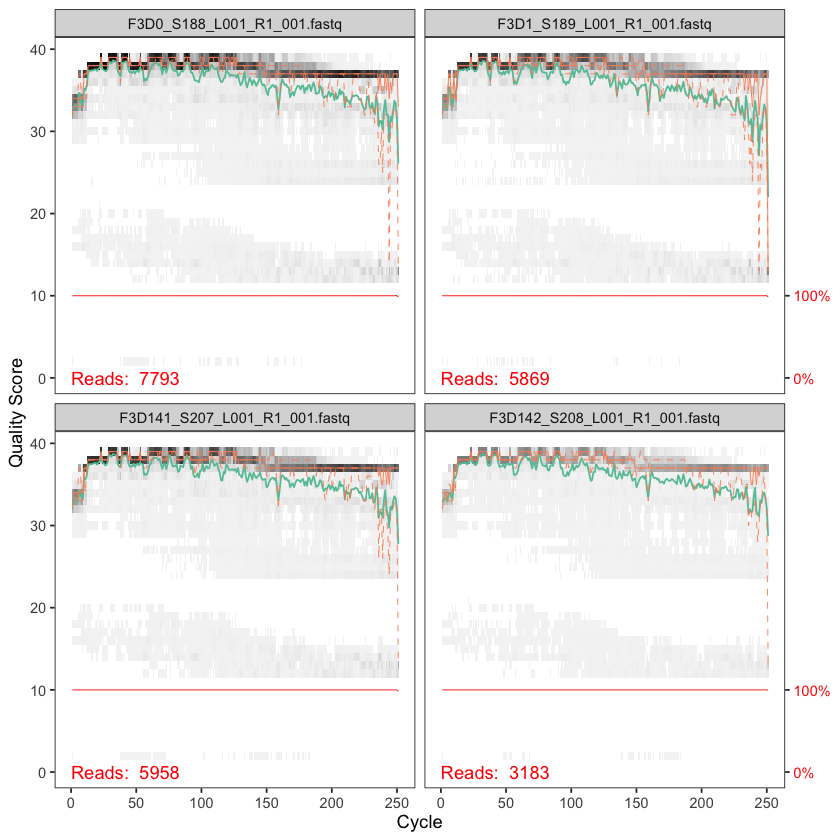

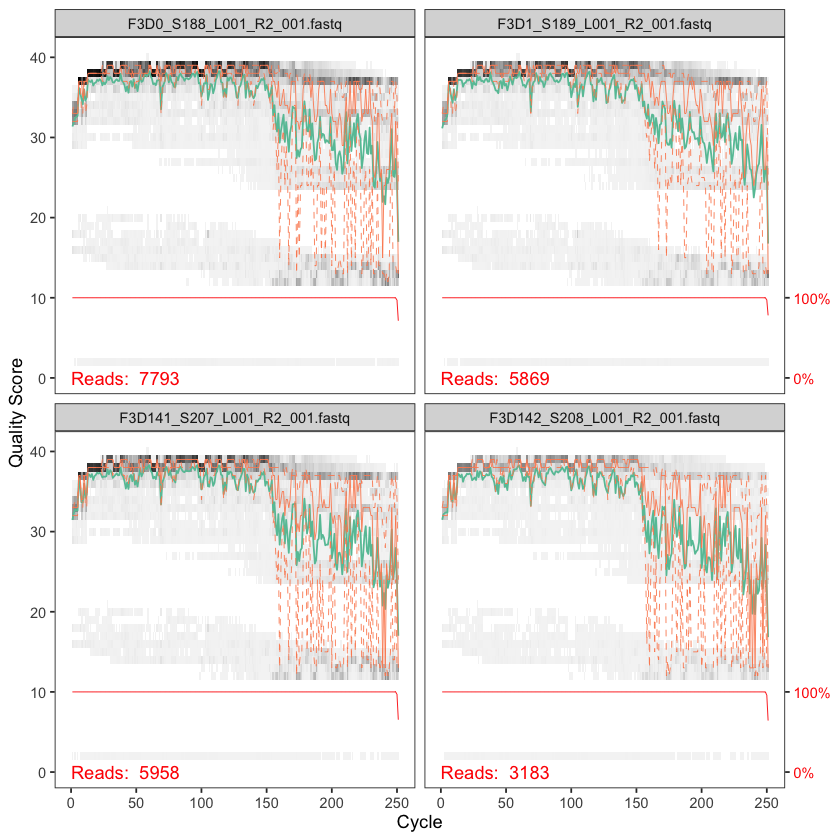

In [9]:
qc_idx <- head(seq_along(fnFs), 4)
plotQualityProfile(fnFs[qc_idx])
plotQualityProfile(fnRs[qc_idx])

## 4. Primer detection and removal (cutadapt)
The first cell counts primer hits in the first 2,000 reads of a few samples. If at least 50% of reads contain the forward primer, cutadapt removes the primers and discards read pairs without them. Otherwise the reads are taken to be primer-free and passed on unchanged. Override with `primers_in_reads = TRUE/FALSE`.

In [10]:
allOrients <- function(p) {
  d <- DNAString(p)
  c(Forward = p, Complement = as.character(complement(d)),
    Reverse = as.character(reverse(d)), RevComp = as.character(reverseComplement(d)))
}
primerHits <- function(primer, fn, n = 2000) {
  fq <- FastqStreamer(fn, n); on.exit(close(fq)); r <- sread(yield(fq))
  sum(vcountPattern(primer, r, fixed = FALSE) > 0)
}
hits <- rbind(FWD.inR1 = sapply(allOrients(params$primer_fwd), primerHits, fn = fnFs[1]),
              REV.inR2 = sapply(allOrients(params$primer_rev), primerHits, fn = fnRs[1]))
print(hits)
chk <- head(seq_along(fnFs), 3)
frac_fwd <- mean(sapply(fnFs[chk], function(f) primerHits(params$primer_fwd, f) / min(2000, length(readFastq(f)))))
use_cutadapt <- if (is.na(params$primers_in_reads)) frac_fwd >= 0.5 else params$primers_in_reads
cat(sprintf("Forward primer found in %.0f%% of reads -> %s\n", 100 * frac_fwd,
            if (use_cutadapt) "primers present: running cutadapt" else "primers absent: skipping cutadapt"))

         Forward Complement Reverse RevComp
FWD.inR1       0          0       0       0
REV.inR2       5          5       6       7
Forward primer found in 0% of reads -> primers absent: skipping cutadapt


In [11]:
if (!use_cutadapt) {
  fnFs.cut <- fnFs; fnRs.cut <- fnRs
} else {
cut_dir <- file.path(params$out_dir, "cutadapt", substr(rlang::hash(params[c("primer_fwd", "primer_rev")]), 1, 10)); dir.create(cut_dir, showWarnings = FALSE, recursive = TRUE)
fnFs.cut <- file.path(cut_dir, basename(fnFs)); fnRs.cut <- file.path(cut_dir, basename(fnRs))
fwd_rc <- as.character(reverseComplement(DNAString(params$primer_fwd)))
rev_rc <- as.character(reverseComplement(DNAString(params$primer_rev)))
for (i in seq_along(fnFs)) {
  if (file.exists(fnFs.cut[i])) next
  system2("cutadapt", c("-g", params$primer_fwd, "-a", rev_rc,          # not anchored: tolerates heterogeneity spacers
                        "-G", params$primer_rev, "-A", fwd_rc,
                        "-n", 2, "--discard-untrimmed", "-j", 0,
                        "-o", fnFs.cut[i], "-p", fnRs.cut[i], fnFs[i], fnRs[i]),
          stdout = file.path(cut_dir, paste0(sample_ids[i], ".log")))
}
# Sanity check: primer hits should now be ~0
print(rbind(FWD.inR1 = sapply(allOrients(params$primer_fwd), primerHits, fn = fnFs.cut[1]),
            REV.inR2 = sapply(allOrients(params$primer_rev), primerHits, fn = fnRs.cut[1])))
}

## 5. Filter and trim
Overlap check: `trunc_len[1] + trunc_len[2] − longest amplicon` must be ≥ `min_overlap` (12 bp), and should be ≥ 20 bp to allow for length variation. Reads shorter than `truncLen` are discarded, so don't set it above the read length (250 bp, or ~231 bp if primers were removed).

In [12]:
# truncLen discards reads shorter than it, so cap it at the actual read length (reads are shorter after primer removal)
read_len <- sapply(list(fnFs.cut, fnRs.cut), function(f) {
  fq <- FastqStreamer(f[1], 2000); on.exit(close(fq))
  as.integer(quantile(width(sread(yield(fq))), 0.05))
})
if (any(params$trunc_len > read_len)) {
  message(sprintf("trunc_len (%s) exceeds read length (%s, 5th percentile); capping it",
                  paste(params$trunc_len, collapse = "/"), paste(read_len, collapse = "/")))
  params$trunc_len <- pmin(params$trunc_len, read_len)
}
cat("trunc_len used:", params$trunc_len, "\n")
overlap <- sum(params$trunc_len) - max(params$amplicon_len)
cat("Expected minimum overlap for the longest amplicon:", overlap, "bp\n")
if (params$mode == "paired") {
  if (overlap < params$min_overlap) stop("trunc_len too short for the longest amplicon to merge")
  if (overlap < 20) warning("Overlap < 20 bp: longer-than-expected amplicons will fail to merge")
}
filt_dir <- file.path(params$out_dir, "filtered")
filtFs <- file.path(filt_dir, paste0(sample_ids, "_F_filt.fastq.gz"))
filtRs <- file.path(filt_dir, paste0(sample_ids, "_R_filt.fastq.gz"))
names(filtFs) <- names(filtRs) <- sample_ids

key_filter <- list(basename(fnFs), file.size(fnFs), file.size(fnRs), use_cutadapt, params[c("primer_fwd", "primer_rev")],
                   params$trunc_len, params$max_ee, params$trunc_q)
filt_out <- cached("filter", key = key_filter, filterAndTrim(
  fnFs.cut, filtFs, fnRs.cut, filtRs,
  truncLen = params$trunc_len, maxN = 0, maxEE = params$max_ee,
  truncQ = params$trunc_q, rm.phix = TRUE, compress = TRUE, multithread = params$threads))
rownames(filt_out) <- sample_ids
if (sum(filt_out[, 2]) == 0) stop("No reads passed filtering: check trunc_len against read length, and max_ee")
summary(filt_out[, 2] / filt_out[, 1])

trunc_len used: 240 160 
Expected minimum overlap for the longest amplicon: 144 bp


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.8933  0.9123  0.9165  0.9154  0.9204  0.9290 

## 6. Error model
There's one run, so one model per read direction. The code still splits by `run_id`, so it handles more runs unchanged. The fitted line (black) should follow the observed points.

33514080 total bases in 139642 reads from 20 samples will be used for learning the error rates.
22342720 total bases in 139642 reads from 20 samples will be used for learning the error rates.


Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”


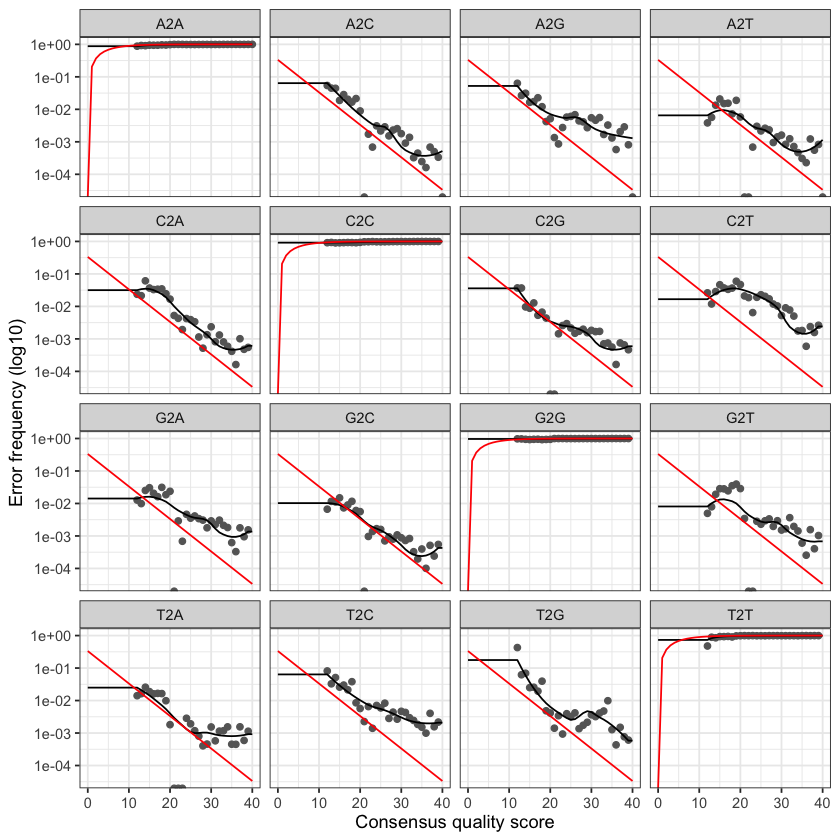

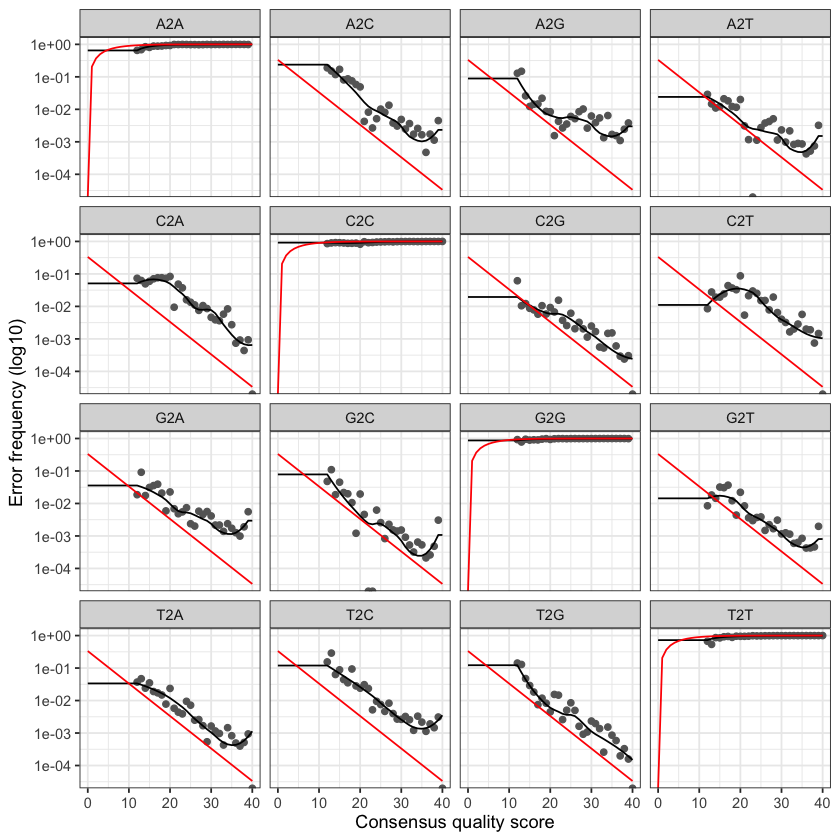

In [13]:
keep <- file.exists(filtFs)          # samples with zero reads after filtering produce no file
runs <- split(sample_ids[keep], meta$run_id[keep])
key_err <- list(key_filter, runs)
errs <- cached("errors", key = key_err, lapply(runs, function(s) list(
  F = learnErrors(filtFs[s], multithread = params$threads),
  R = learnErrors(filtRs[s], multithread = params$threads))))
plotErrors(errs[[1]]$F, nominalQ = TRUE)
plotErrors(errs[[1]]$R, nominalQ = TRUE)

## 7–8. Denoise and merge
For V4 on 2×250, expect more than 90% of denoised reads to merge. A low merge rate usually means `trunc_len` is too short or the amplicon isn't V4. `forward_only` mode is a fallback for very poor reverse reads.

In [14]:
key_dada <- list(key_err, params[c("mode", "pool", "min_overlap")])
seqtabs <- cached("seqtabs", key = key_dada, setNames(lapply(names(runs), function(r) {
  s  <- runs[[r]]
  dF <- dada(filtFs[s], err = errs[[r]]$F, pool = params$pool, multithread = params$threads)
  if (length(s) == 1) dF <- setNames(list(dF), s)
  if (params$mode == "forward_only") {
    return(list(seqtab = makeSequenceTable(dF),
                track  = cbind(denoisedF = sapply(dF, getN), denoisedR = NA, merged = NA)))
  }
  dR <- dada(filtRs[s], err = errs[[r]]$R, pool = params$pool, multithread = params$threads)
  if (length(s) == 1) dR <- setNames(list(dR), s)
  mg <- mergePairs(dF, filtFs[s], dR, filtRs[s], minOverlap = params$min_overlap)
  if (length(s) == 1) mg <- setNames(list(mg), s)
  list(seqtab = makeSequenceTable(mg),
       track  = cbind(denoisedF = sapply(dF, getN), denoisedR = sapply(dR, getN),
                      merged = sapply(mg, getN)))
}), names(runs)))

if (params$mode == "paired") {
  tr <- do.call(rbind, lapply(seqtabs, `[[`, "track"))
  merge_rate <- tr[, "merged"] / pmin(tr[, "denoisedF"], tr[, "denoisedR"])
  print(summary(merge_rate))
  if (median(merge_rate, na.rm = TRUE) < params$min_merge_rate)
    warning(sprintf("Median merge rate %.0f%% is low. Options: lower trunc_len[2]/raise max_ee, or set mode = 'forward_only'.",
                    100 * median(merge_rate, na.rm = TRUE)))
}

Sample 1 - 7113 reads in 1979 unique sequences.
Sample 2 - 5299 reads in 1639 unique sequences.
Sample 3 - 5463 reads in 1477 unique sequences.
Sample 4 - 2914 reads in 904 unique sequences.
Sample 5 - 2941 reads in 939 unique sequences.
Sample 6 - 4312 reads in 1267 unique sequences.
Sample 7 - 6741 reads in 1756 unique sequences.
Sample 8 - 4560 reads in 1438 unique sequences.
Sample 9 - 15637 reads in 3590 unique sequences.
Sample 10 - 11413 reads in 2762 unique sequences.
Sample 11 - 12017 reads in 3021 unique sequences.
Sample 12 - 5032 reads in 1566 unique sequences.
Sample 13 - 18075 reads in 3707 unique sequences.
Sample 14 - 6250 reads in 1479 unique sequences.
Sample 15 - 4052 reads in 1195 unique sequences.
Sample 16 - 7369 reads in 1832 unique sequences.
Sample 17 - 4765 reads in 1183 unique sequences.
Sample 18 - 4871 reads in 1382 unique sequences.
Sample 19 - 6504 reads in 1709 unique sequences.
Sample 20 - 4314 reads in 897 unique sequences.

   selfConsist step 2Sample

## 9. ASV table and chimera removal
Check the length distribution first. For V4, nearly all ASVs should be 252–254 bp; peaks far outside 250–256 are non-specific amplification. A large share of chimeric reads, more than about 15–20%, usually means primers were left on the reads.

In [15]:
seqtab <- if (length(seqtabs) > 1) mergeSequenceTables(tables = lapply(seqtabs, `[[`, "seqtab")) else seqtabs[[1]]$seqtab
print(table(nchar(colnames(seqtab))))
if (params$mode == "paired")
  seqtab <- seqtab[, nchar(colnames(seqtab)) %in% seq(params$amplicon_len[1], params$amplicon_len[2]), drop = FALSE]
if (ncol(seqtab) == 0) stop("No ASVs in the expected length range ", paste(params$amplicon_len, collapse = "-"),
                           " bp. Check the length table above against amplicon_len, and whether primers_in_reads is right for your data.")

key_nochim <- list(key_dada, params$amplicon_len)
seqtab.nochim <- cached("seqtab_nochim", key = key_nochim,
  removeBimeraDenovo(seqtab, method = "consensus", multithread = params$threads))
cat(sprintf("ASVs: %d -> %d; reads kept after chimera removal: %.1f%%\n",
            ncol(seqtab), ncol(seqtab.nochim), 100 * sum(seqtab.nochim) / sum(seqtab)))


251 252 253 254 255 
  1  87 197   5   2 
ASVs: 292 -> 232; reads kept after chimera removal: 95.2%


## 10. Read tracking
This shows where reads are lost. For V4, the biggest drop is normally at `filtered`.

,sample_id,input,filtered,denoisedF,denoisedR,merged,nonchim,pct_retained,sample_type
,<chr>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>
1,F3D144,4827,4312,4260,4279,3970,3704,76.7,sample
2,F3D147,17070,15637,15457,15551,14327,13112,76.8,sample
3,F3D145,7377,6741,6677,6706,6215,5779,78.3,sample
4,F3D148,12405,11413,11285,11333,10584,9909,79.9,sample
5,F3D146,5021,4560,4493,4521,4234,4019,80.0,sample
6,F3D142,3183,2914,2883,2896,2703,2552,80.2,sample
7,F3D150,5509,5032,4955,4980,4663,4440,80.6,sample
8,F3D143,3178,2941,2889,2909,2701,2568,80.8,sample
9,F3D149,13083,12017,11904,11951,11305,10707,81.8,sample


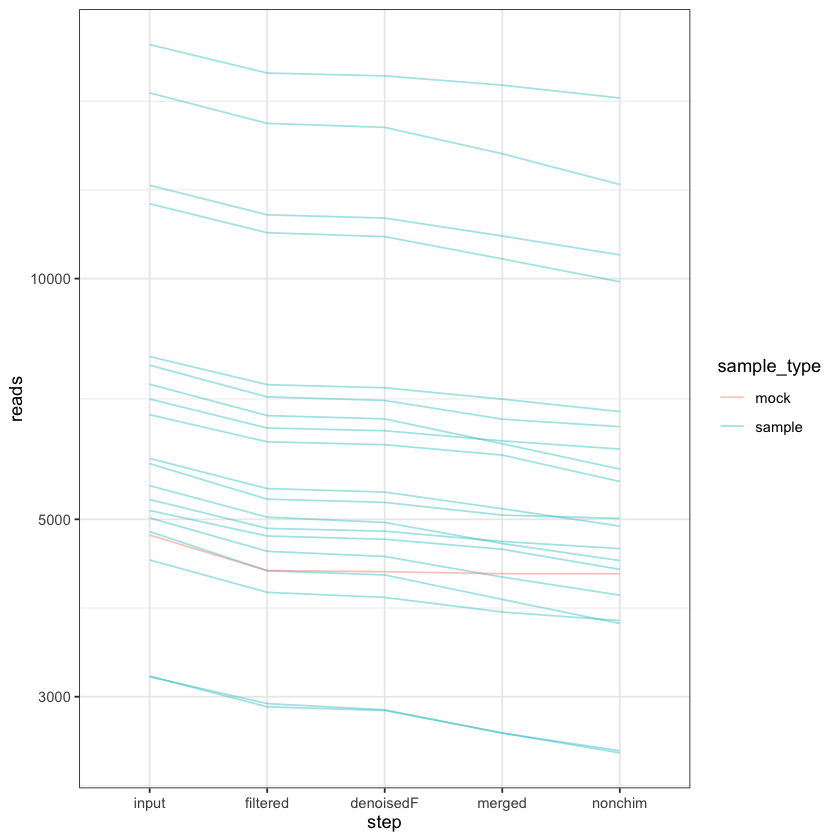

In [16]:
dn <- do.call(rbind, lapply(seqtabs, `[[`, "track"))
track <- data.frame(sample_id = sample_ids, input = filt_out[, 1], filtered = filt_out[, 2]) |>
  left_join(rownames_to_column(as.data.frame(dn), "sample_id"), by = "sample_id") |>
  mutate(nonchim = unname(rowSums(seqtab.nochim)[sample_id]),
         nonchim = coalesce(nonchim, 0),
         pct_retained = round(100 * nonchim / input, 1),
         sample_type = meta$sample_type)
write.table(track, file.path(params$out_dir, "read_tracking.tsv"), sep = "\t", row.names = FALSE, quote = FALSE)
track |> pivot_longer(c(input, filtered, denoisedF, merged, nonchim), names_to = "step", values_to = "reads") |>
  mutate(step = factor(step, c("input", "filtered", "denoisedF", "merged", "nonchim"))) |>
  ggplot(aes(step, reads, group = sample_id, colour = sample_type)) + geom_line(alpha = .4) +
  scale_y_log10() + theme_bw()
arrange(track, pct_retained) |> head(10)

## 11. Taxonomy (SILVA 138.2, DADA2-formatted)
Download the training files from Zenodo record 14169026 and cite it in Methods.

In [17]:
taxa <- cached("taxa", key = list(key_nochim, params[c("silva_train", "silva_species")]), {
  t <- assignTaxonomy(seqtab.nochim, params$silva_train, multithread = params$threads)
  if (params$mode == "paired") addSpecies(t, params$silva_species) else t
})
round(100 * colSums(!is.na(taxa)) / nrow(taxa), 1)    # % of ASVs classified at each rank

Kingdom  Phylum   Class   Order  Family   Genus Species 
  100.0   100.0   100.0   100.0    90.9    55.6     6.9

### 11b. Mock community check (optional)
Runs only if a sample has `sample_type = mock`. Counts the ASVs found in the mock sample. If `mock_ref` points to a FASTA of the strains' true sequences, it also reports how many ASVs exactly match a reference strain. Ideally every ASV with a reasonable abundance matches, and the number of ASVs is close to the number of strains.

In [18]:
is_mock <- meta$sample_type[match(rownames(seqtab.nochim), meta$sample_id)] == "mock"
if (any(is_mock)) {
  for (m in rownames(seqtab.nochim)[is_mock]) {
    v <- sort(seqtab.nochim[m, ][seqtab.nochim[m, ] > 0], decreasing = TRUE)
    cat(sprintf("%s: %d ASVs, %d reads\n", m, length(v), sum(v)))
    if (!is.null(params$mock_ref) && file.exists(params$mock_ref)) {
      ref <- as.character(readDNAStringSet(params$mock_ref))
      exact <- sapply(names(v), function(s) any(grepl(s, ref, fixed = TRUE)))
      cat(sprintf("  %d of %d ASVs exactly match a reference strain (%.1f%% of reads); reference has %d strains\n",
                  sum(exact), length(v), 100 * sum(v[exact]) / sum(v), length(ref)))
    }
  }
} else message("No mock sample in metadata: skipped")

Mock: 26 ASVs, 4275 reads


## 12. Contaminants and off-target taxa
**With a single negative control,** decontam's prevalence method has little power: it can only see whether an ASV is present in that one control. To compensate:
- The default threshold is 0.5 (more aggressive than decontam's 0.1).
- If `dna_conc_col` is set, the frequency method is added (`method = "either"`).
- Every ASV in the control is listed for manual review. Abundant taxa that are real in your samples will cross-contaminate into the control, so don't remove them just because they show up there.

In [19]:
is_neg <- meta$sample_type[match(rownames(seqtab.nochim), meta$sample_id)] == "neg_control"
has_conc <- !is.null(params$dna_conc_col) && params$dna_conc_col %in% names(meta)
if (any(is_neg)) {
  conc <- NULL
  if (has_conc) {
    conc <- as.numeric(meta[[params$dna_conc_col]][match(rownames(seqtab.nochim), meta$sample_id)])
    conc[is.na(conc) | conc <= 0] <- min(conc[conc > 0], na.rm = TRUE) / 2
  }
  contam <- isContaminant(seqtab.nochim, neg = is_neg, conc = conc,
                          method = if (has_conc) "either" else "prevalence",
                          threshold = params$decontam_threshold)
} else {
  contam <- data.frame(contaminant = rep(FALSE, ncol(seqtab.nochim)))
  warning("No negative controls: contaminant screening skipped")
}
cat("Flagged contaminants:", sum(contam$contaminant), "\n")

# Manual review: everything seen in the negative control(s)
neg_reads <- colSums(seqtab.nochim[is_neg, , drop = FALSE])
neg_review <- data.frame(
  reads_in_neg = neg_reads,
  prevalence_in_samples = colSums(seqtab.nochim[!is_neg, , drop = FALSE] > 0),
  mean_reads_in_samples = round(colMeans(seqtab.nochim[!is_neg, , drop = FALSE])),
  genus = taxa[, "Genus"], flagged = contam$contaminant, row.names = NULL)[neg_reads > 0, ] |>
  arrange(desc(reads_in_neg))
cat("Negative control depth:", sum(neg_reads), "reads; median sample depth:",
    median(rowSums(seqtab.nochim[!is_neg, , drop = FALSE])), "\n")
head(neg_review, 25)

Warning message:
“No negative controls: contaminant screening skipped”


Flagged contaminants: 0 
Negative control depth: 0 reads; median sample depth: 4958 


reads_in_neg,prevalence_in_samples,mean_reads_in_samples,genus,flagged
<dbl>,<dbl>,<dbl>,<chr>,<lgl>


In [20]:
offtarget <- !(taxa[, "Kingdom"] %in% c("Bacteria", "Archaea")) |
             taxa[, "Order"]  %in% "Chloroplast" |
             taxa[, "Family"] %in% "Mitochondria"
keep_asv <- !contam$contaminant & !offtarget
seqtab.clean <- seqtab.nochim[, keep_asv, drop = FALSE]
taxa.clean   <- taxa[keep_asv, , drop = FALSE]
cat(sprintf("ASVs kept: %d of %d (contaminants %d, off-target %d)\n",
            sum(keep_asv), length(keep_asv), sum(contam$contaminant), sum(offtarget)))

ASVs kept: 228 of 232 (contaminants 0, off-target 4)


## 13. phyloseq object and export
Files written to `results/`:

| file | contents |
|---|---|
| `asv_counts.tsv` | `ASV_ID` + one column of read counts per sample |
| `asv_taxonomy.tsv` | `ASV_ID` + Kingdom … Species (empty where unassigned) |
| `asv_report.tsv` | taxonomy, sequence, length, total reads, % of reads, number of samples detected in, and per-sample counts, sorted by abundance |
| `asv_seqs.fasta` | ASV sequences, named `ASV1`, `ASV2`, … |
| `phyloseq.rds` / `phyloseq_with_controls.rds` | phyloseq objects for R |

Controls and the mock are kept in the exported tables but dropped from `ps` before the biological analysis.

In [21]:
sd <- meta; rownames(sd) <- sd$sample_id
ps_all <- phyloseq(otu_table(seqtab.clean, taxa_are_rows = FALSE),
                   sample_data(sd[rownames(seqtab.clean), ]),
                   tax_table(taxa.clean))
dna <- DNAStringSet(taxa_names(ps_all)); names(dna) <- taxa_names(ps_all)
ps_all <- merge_phyloseq(ps_all, dna)
taxa_names(ps_all) <- paste0("ASV", seq(ntaxa(ps_all)))

saveRDS(ps_all, file.path(params$out_dir, "phyloseq_with_controls.rds"))
writeXStringSet(refseq(ps_all), file.path(params$out_dir, "asv_seqs.fasta"))
# ASV IDs are written as an explicit first column: write.table(row.names = TRUE) leaves no header cell for them,
# which shifts every column header one position to the left
counts_df <- data.frame(ASV_ID = taxa_names(ps_all), t(as(otu_table(ps_all), "matrix")), check.names = FALSE)
tax_df    <- data.frame(ASV_ID = taxa_names(ps_all), as(tax_table(ps_all), "matrix"), check.names = FALSE)
write.table(counts_df, file.path(params$out_dir, "asv_counts.tsv"),   sep = "\t", quote = FALSE, row.names = FALSE)
write.table(tax_df,    file.path(params$out_dir, "asv_taxonomy.tsv"), sep = "\t", quote = FALSE, row.names = FALSE, na = "")

# Combined report: one row per ASV with taxonomy, sequence, totals and per-sample counts, most abundant first.
# Includes controls/mock so they can be inspected; sample_type is in metadata.tsv.
sample_cols <- setdiff(names(counts_df), "ASV_ID")
report <- tax_df |>
  left_join(data.frame(ASV_ID = taxa_names(ps_all), sequence = as.character(refseq(ps_all))), by = "ASV_ID") |>
  mutate(length = nchar(sequence)) |>
  left_join(counts_df, by = "ASV_ID") |>
  mutate(total_reads = rowSums(across(all_of(sample_cols))),
         pct_of_reads = round(100 * total_reads / sum(total_reads), 4),
         n_samples = rowSums(across(all_of(sample_cols), ~ .x > 0)),
         .after = length) |>
  arrange(desc(total_reads))
write.table(report, file.path(params$out_dir, "asv_report.tsv"), sep = "\t", quote = FALSE, row.names = FALSE, na = "")
cat("Wrote asv_counts.tsv, asv_taxonomy.tsv, asv_report.tsv (", nrow(report), "ASVs x", length(sample_cols), "samples)\n")

ps <- prune_samples(sample_data(ps_all)$sample_type == "sample", ps_all)
ps <- prune_taxa(taxa_sums(ps) > 0, ps)
saveRDS(ps, file.path(params$out_dir, "phyloseq.rds"))
ps

Wrote asv_counts.tsv, asv_taxonomy.tsv, asv_report.tsv ( 228 ASVs x 20 samples)


phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 214 taxa and 19 samples ]
sample_data() Sample Data:       [ 19 samples by 5 sample variables ]
tax_table()   Taxonomy Table:    [ 214 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 214 reference sequences ]

## 14. Downstream analysis (driven by the metadata)
This section runs on whatever study variables are in `metadata.tsv`. You don't need to edit any code here:
- **Categorical variables** (2–10 levels, e.g. treatment, timepoint, site): alpha-diversity tests, PCoA, PERMANOVA + dispersion test, composition plots, differential abundance.
- **Numeric variables** (e.g. age, BMI): Spearman correlation with alpha diversity, PERMANOVA.
- ID-like columns (all values unique) and the bookkeeping columns are ignored.
- If no study variables are found, only the descriptive parts (depth, diversity distributions, composition) run.

Each variable is tested on its own (marginal tests). Covariate adjustment, repeated measures and interactions depend on the study design: add them once the question is fixed.

Extra packages: `vegan`, `ANCOMBC`, `ALDEx2`. Differential abundance is skipped automatically if they're missing.

In [22]:
suppressPackageStartupMessages(library(vegan))
ds_dir <- file.path(params$out_dir, "downstream"); dir.create(ds_dir, showWarnings = FALSE, recursive = TRUE)

sdf <- data.frame(sample_data(ps), check.names = FALSE)
reserved <- c("sample_id", "run_id", "sample_type", params$dna_conc_col)
cand <- setdiff(names(sdf), reserved)
n_lev <- function(x) length(unique(na.omit(x)))
is_cat <- function(x) (is.character(x) || is.factor(x) || is.logical(x)) && n_lev(x) >= 2 && n_lev(x) <= 10
is_num <- function(x) is.numeric(x) && n_lev(x) > 5
group_vars <- if (length(params$group_vars)) params$group_vars else Filter(function(v) is_cat(sdf[[v]]), cand)
num_vars   <- if (length(params$num_vars))   params$num_vars   else Filter(function(v) is_num(sdf[[v]]), cand)
# Small-integer numerics (e.g. timepoint coded 1/2/3) are treated as categorical
group_vars <- union(group_vars, if (!length(params$group_vars))
  Filter(function(v) is.numeric(sdf[[v]]) && n_lev(sdf[[v]]) %in% 2:5, cand))
num_vars <- setdiff(num_vars, group_vars)
cat("Categorical variables:", if (length(group_vars)) group_vars else "none", "\n")
cat("Numeric variables:    ", if (length(num_vars)) num_vars else "none", "\n")
run_tests <- length(c(group_vars, num_vars)) > 0

Categorical variables: none 
Numeric variables:     timepoint 


### 14.1 Sequencing depth and rarefaction

Samples below min_depth (dropped): 9 (F3D141, F3D142, F3D143, F3D144, F3D146, F3D150, F3D5, F3D7, F3D8) 


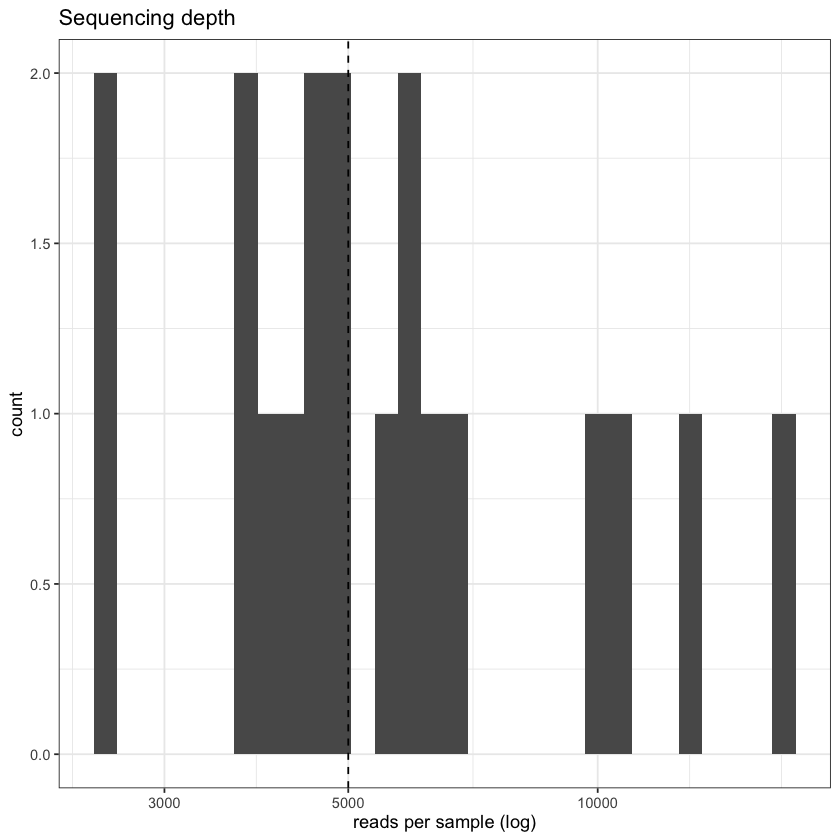

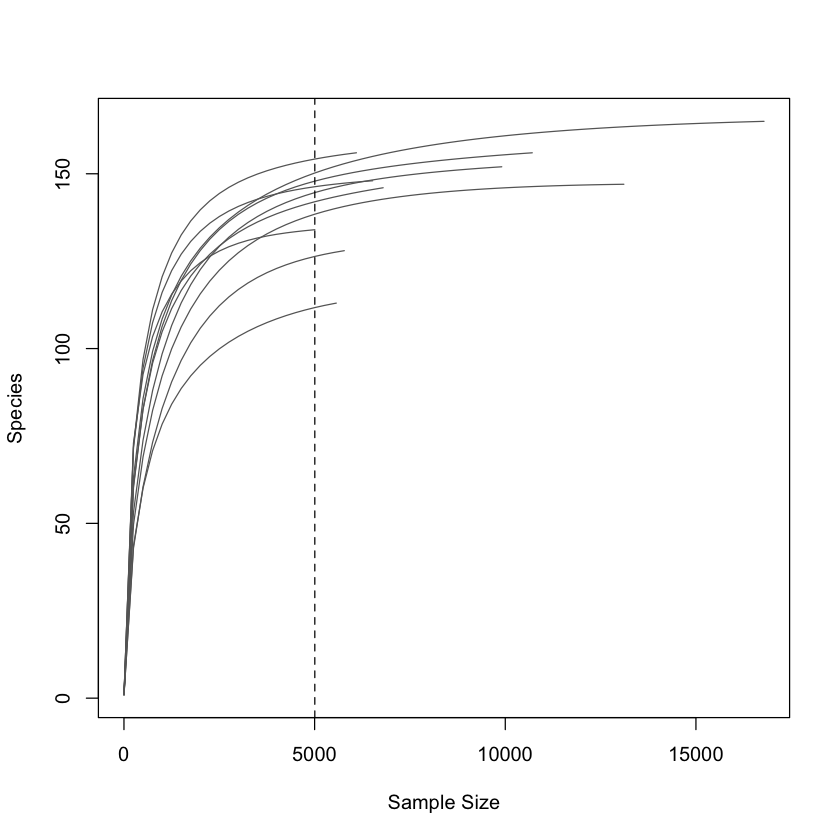

In [23]:
depth <- sample_sums(ps)
print(ggplot(data.frame(depth), aes(depth)) + geom_histogram(bins = 30) +
        geom_vline(xintercept = params$min_depth, linetype = 2) + scale_x_log10() +
        labs(x = "reads per sample (log)", title = "Sequencing depth") + theme_bw())
dropped <- names(depth)[depth < params$min_depth]
cat("Samples below min_depth (dropped):", length(dropped), if (length(dropped)) paste0("(", paste(dropped, collapse = ", "), ")"), "\n")

ps_f <- prune_samples(depth >= params$min_depth, ps)
ps_f <- prune_taxa(taxa_sums(ps_f) > 0, ps_f)
otu_f <- as(otu_table(ps_f), "matrix")
rarecurve(otu_f, step = max(100, floor(min(rowSums(otu_f)) / 20)), label = FALSE, col = "grey40")
abline(v = min(rowSums(otu_f)), lty = 2)

# Rarefied copy is used for richness metrics and Bray-Curtis only; CLR-based analyses use unrarefied counts
ps_rare <- rarefy_even_depth(ps_f, sample.size = min(sample_sums(ps_f)), rngseed = params$seed, verbose = FALSE)
md_f <- data.frame(sample_data(ps_f), check.names = FALSE)

### 14.2 Alpha diversity
Observed ASVs and Shannon index, computed on the rarefied table. Two-level variables use the Wilcoxon test; more levels use Kruskal–Wallis; numeric variables use Spearman correlation. P-values are BH-adjusted within this section.

   variable   metric                 test         p     p_adj
1 timepoint Observed  Spearman rho = 0.12 0.7379380 0.7379380
2 timepoint  Shannon Spearman rho = -0.42 0.2324181 0.4648362


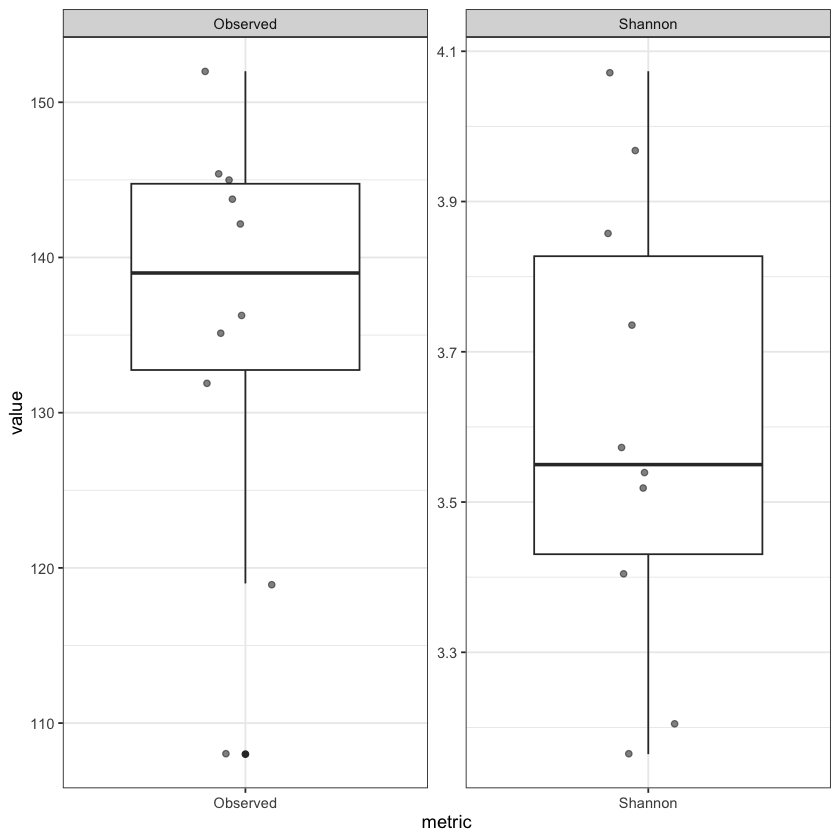

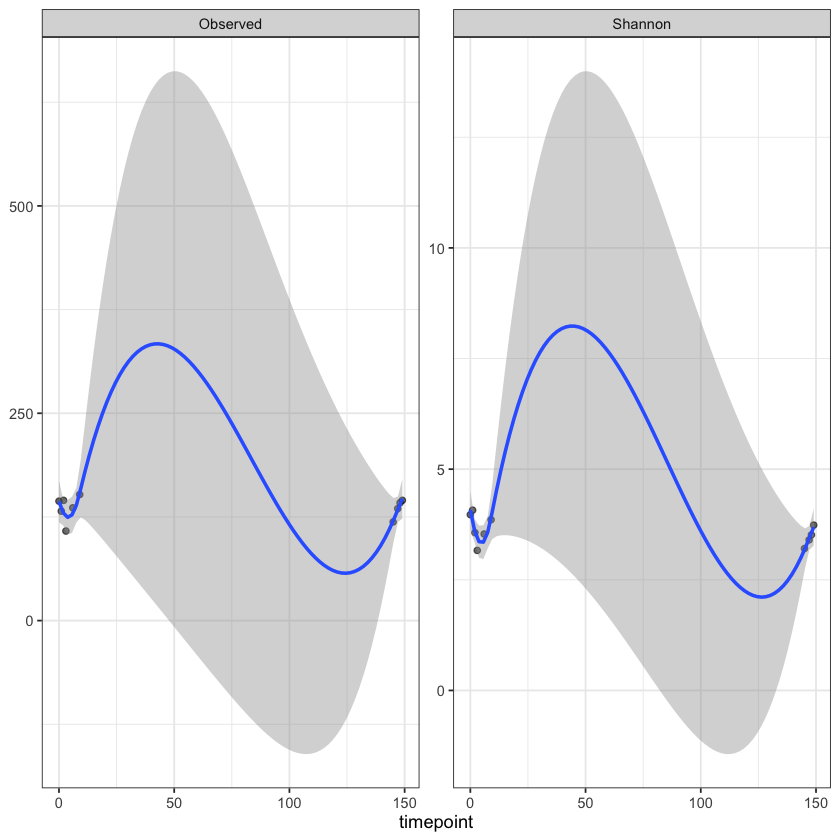

In [24]:
alpha <- cbind(estimate_richness(ps_rare, measures = c("Observed", "Shannon")),
               data.frame(sample_data(ps_rare), check.names = FALSE))
write.table(alpha, file.path(ds_dir, "alpha_diversity.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
metrics <- c("Observed", "Shannon")

alpha_tests <- list()
for (v in group_vars) for (m in metrics) {
  d <- alpha[!is.na(alpha[[v]]), ]; g <- factor(d[[v]])
  t <- if (nlevels(g) == 2) wilcox.test(d[[m]] ~ g, exact = FALSE) else kruskal.test(d[[m]] ~ g)
  alpha_tests[[length(alpha_tests) + 1]] <- data.frame(variable = v, metric = m, test = t$method, p = t$p.value)
}
for (v in num_vars) for (m in metrics) {
  t <- suppressWarnings(cor.test(alpha[[m]], alpha[[v]], method = "spearman"))
  alpha_tests[[length(alpha_tests) + 1]] <- data.frame(variable = v, metric = m,
                                                       test = sprintf("Spearman rho = %.2f", t$estimate), p = t$p.value)
}
if (length(alpha_tests)) {
  alpha_tests <- bind_rows(alpha_tests) |> mutate(p_adj = p.adjust(p, "BH"))
  write.table(alpha_tests, file.path(ds_dir, "alpha_tests.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
  print(alpha_tests)
}

alpha_long <- pivot_longer(alpha, all_of(metrics), names_to = "metric", values_to = "value")
if (!length(group_vars)) {
  print(ggplot(alpha_long, aes(metric, value)) + geom_boxplot() + geom_jitter(width = .15, alpha = .5) +
          facet_wrap(~metric, scales = "free") + theme_bw())
}
for (v in group_vars) {
  print(ggplot(filter(alpha_long, !is.na(.data[[v]])), aes(factor(.data[[v]]), value)) +
          geom_boxplot(outlier.shape = NA) + geom_jitter(width = .15, alpha = .5) +
          facet_wrap(~metric, scales = "free_y") + labs(x = v, y = NULL, title = paste("Alpha diversity by", v)) + theme_bw())
}
for (v in num_vars) {
  print(ggplot(alpha_long, aes(.data[[v]], value)) + geom_point(alpha = .6) + geom_smooth(method = "loess", formula = y ~ x) +
          facet_wrap(~metric, scales = "free_y") + labs(x = v, y = NULL) + theme_bw())
}

### 14.3 Beta diversity
**Aitchison** (Euclidean distance on CLR-transformed counts, unrarefied; compositionally appropriate) and **Bray–Curtis** (rarefied). PERMANOVA tests whether groups differ in centroid. `betadisper` tests whether they differ in spread. A significant PERMANOVA together with a significant dispersion test needs cautious interpretation.

# A tibble: 2 × 7
  distance   variable      n    R2     p dispersion_p p_adj
  <chr>      <chr>     <int> <dbl> <dbl> <lgl>        <dbl>
1 Aitchison  timepoint    10 0.423 0.005 NA           0.005
2 BrayCurtis timepoint    10 0.420 0.005 NA           0.005


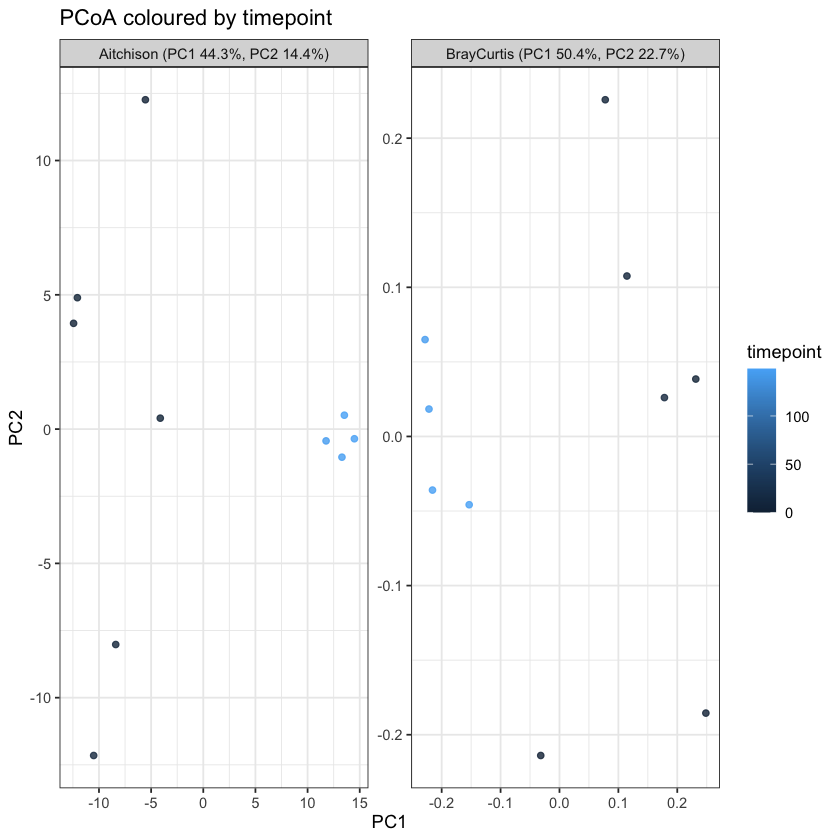

In [25]:
clr <- function(m) { l <- log(m + 0.5); l - rowMeans(l) }
dists <- list(Aitchison  = dist(clr(otu_f)),
              BrayCurtis = vegdist(as(otu_table(ps_rare), "matrix"), method = "bray"))
md_r <- data.frame(sample_data(ps_rare), check.names = FALSE)
md_by_dist <- list(Aitchison = md_f, BrayCurtis = md_r)

pcoa_df <- bind_rows(lapply(names(dists), function(dn) {
  pc <- cmdscale(dists[[dn]], k = 2, eig = TRUE)
  ve <- round(100 * pc$eig[1:2] / sum(pc$eig[pc$eig > 0]), 1)
  data.frame(distance = paste0(dn, " (PC1 ", ve[1], "%, PC2 ", ve[2], "%)"),
             PC1 = pc$points[, 1], PC2 = pc$points[, 2], md_by_dist[[dn]], check.names = FALSE)
}))
if (!length(c(group_vars, num_vars)))
  print(ggplot(pcoa_df, aes(PC1, PC2)) + geom_point() + facet_wrap(~distance, scales = "free") + theme_bw())
for (v in c(group_vars, num_vars)) {
  p <- ggplot(filter(pcoa_df, !is.na(.data[[v]])), aes(PC1, PC2, colour = if (v %in% group_vars) factor(.data[[v]]) else .data[[v]])) +
    geom_point(alpha = .8) + facet_wrap(~distance, scales = "free") + labs(colour = v, title = paste("PCoA coloured by", v)) + theme_bw()
  if (v %in% group_vars) p <- p + stat_ellipse(level = .9, linetype = 2)
  print(p)
}

if (run_tests) {
  perm <- list()
  for (dn in names(dists)) for (v in c(group_vars, num_vars)) {
    mdv <- md_by_dist[[dn]]; ok <- !is.na(mdv[[v]])
    d   <- as.dist(as.matrix(dists[[dn]])[ok, ok])
    x   <- if (v %in% group_vars) factor(mdv[[v]][ok]) else mdv[[v]][ok]
    set.seed(params$seed)
    a <- adonis2(d ~ x, data = data.frame(x = x), permutations = 999)
    disp_p <- if (v %in% group_vars) permutest(betadisper(d, x), permutations = 999)$tab[1, "Pr(>F)"] else NA
    perm[[length(perm) + 1]] <- data.frame(distance = dn, variable = v, n = sum(ok),
                                           R2 = round(a$R2[1], 4), p = a$`Pr(>F)`[1], dispersion_p = disp_p)
  }
  perm <- bind_rows(perm) |> group_by(distance) |> mutate(p_adj = p.adjust(p, "BH")) |> ungroup()
  write.table(perm, file.path(ds_dir, "permanova.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
  print(perm)
}

### 14.4 Taxonomic composition
Top genera by mean relative abundance. ASVs without a genus assignment are pooled as `Unclassified`.

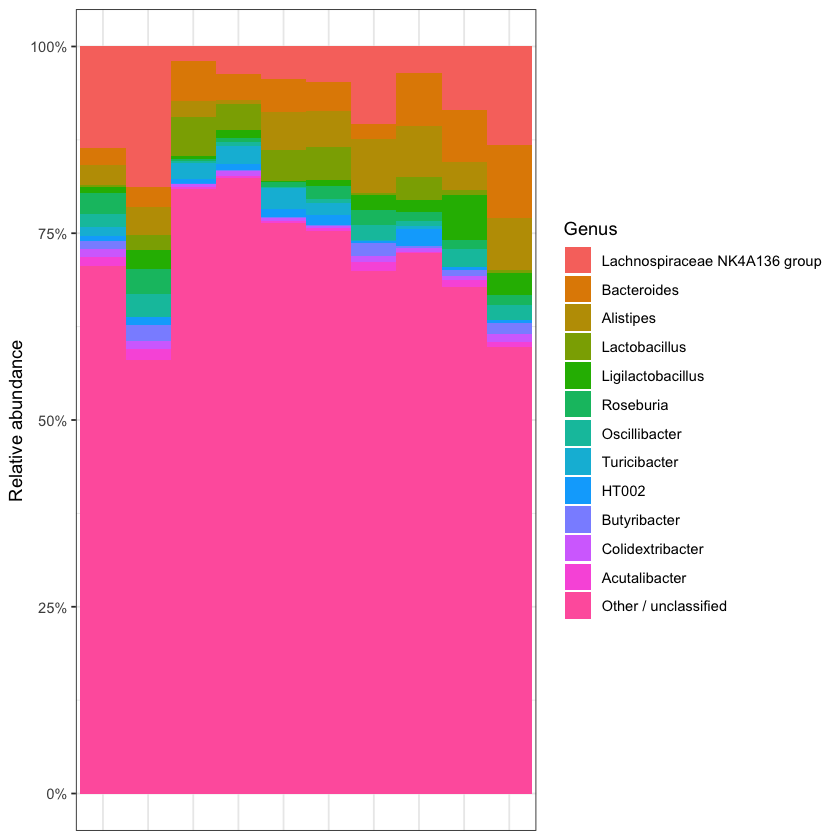

In [26]:
ps_genus <- tax_glom(ps_f, "Genus", NArm = FALSE)
comp <- psmelt(transform_sample_counts(ps_genus, function(x) x / sum(x))) |>
  mutate(Genus = coalesce(as.character(Genus), "Unclassified"))
top_genera <- comp |> group_by(Genus) |> summarise(m = mean(Abundance)) |>
  filter(Genus != "Unclassified") |> slice_max(m, n = 12) |> pull(Genus)
comp <- comp |> mutate(Genus = ifelse(Genus %in% top_genera, Genus, "Other / unclassified"),
                       Genus = factor(Genus, c(top_genera, "Other / unclassified"))) |>
  group_by(Sample, Genus, across(any_of(c(group_vars, num_vars)))) |> summarise(Abundance = sum(Abundance), .groups = "drop")
write.table(comp, file.path(ds_dir, "genus_composition_top.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)

base_bar <- function(d) ggplot(d, aes(Sample, Abundance, fill = Genus)) + geom_col(width = 1) +
  scale_y_continuous(labels = scales::percent) + labs(x = NULL, y = "Relative abundance") +
  theme_bw() + theme(axis.text.x = element_blank(), axis.ticks.x = element_blank())
if (!length(group_vars)) print(base_bar(comp))
for (v in group_vars)
  print(base_bar(filter(comp, !is.na(.data[[v]]))) + facet_grid(cols = vars(.data[[v]]), scales = "free_x", space = "free_x") +
          ggtitle(paste("Genus composition by", v)))

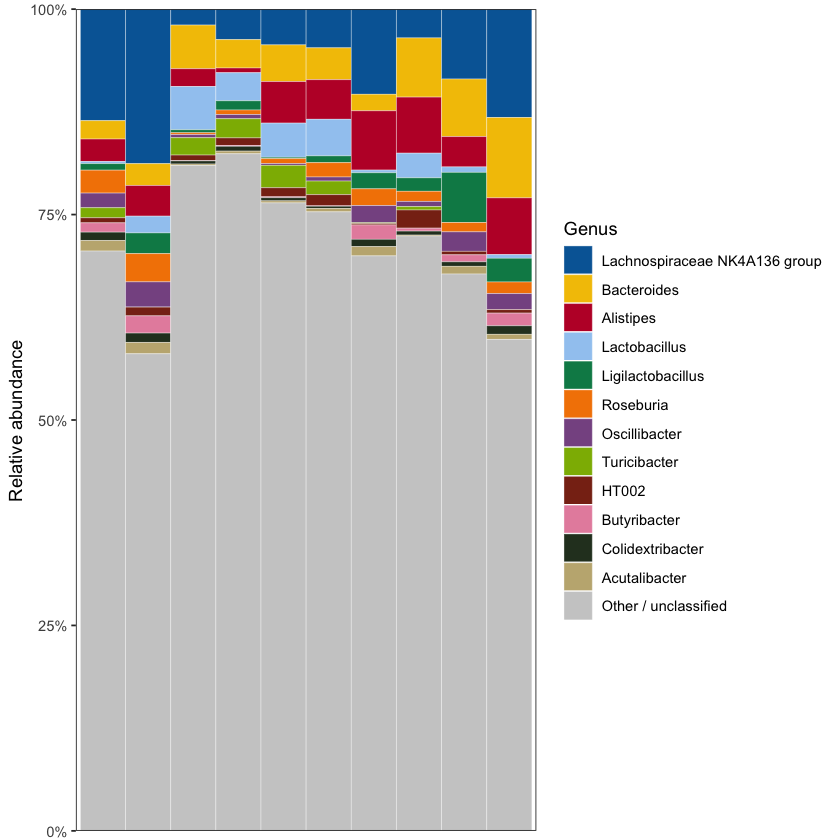

In [30]:
# High-contrast palette (based on Kelly's colors), ordered so dark and light alternate
# in the stack. "Other" is a neutral grey.
genus_pal <- c("#0067A5", "#F3C300", "#BE0032", "#A1CAF1", "#008856", "#F38400",
               "#875692", "#8DB600", "#882D17", "#E68FAC", "#2B3D26", "#C2B280")
fill_vals <- c(setNames(genus_pal[seq_along(top_genera)], top_genera),
               "Other / unclassified" = "grey80")

base_bar <- function(d) ggplot(d, aes(Sample, Abundance, fill = Genus)) +
  geom_col(width = 1, colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = fill_vals, drop = FALSE) +
  scale_y_continuous(labels = scales::percent, expand = c(0, 0)) +
  labs(x = NULL, y = "Relative abundance") +
  theme_bw() +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
        panel.grid = element_blank(),
        legend.key = element_rect(colour = "white"))

if (!length(group_vars)) print(base_bar(comp))
for (v in group_vars)
  print(base_bar(filter(comp, !is.na(.data[[v]]))) +
          facet_grid(cols = vars(.data[[v]]), scales = "free_x", space = "free_x") +
          ggtitle(paste("Genus composition by", v)))

### 14.5 Differential abundance (genus level)
Two compositionally aware methods are run for each categorical variable, and genera called by both are reported as the consensus:
- **ANCOM-BC2**: bias-corrected log fold changes, each level compared with the first (reference) level; global test when there are more than 2 levels. Holm-adjusted.
- **ALDEx2**: CLR with Monte Carlo sampling; Wilcoxon for 2 levels, Kruskal–Wallis for more. BH-adjusted.

Genera present in fewer than 10% of samples are excluded. Numeric variables are skipped here; add them to the ANCOM-BC2 `fix_formula` once covariates are decided.

In [27]:
has_ancombc <- requireNamespace("ANCOMBC", quietly = TRUE)
has_aldex   <- requireNamespace("ALDEx2", quietly = TRUE)
if (!has_ancombc || !has_aldex) message("Missing: ", paste(c("ANCOMBC", "ALDEx2")[!c(has_ancombc, has_aldex)], collapse = ", "),
                                        " -> those methods are skipped")

genus_label <- function(p) {
  tt <- as(tax_table(p), "matrix")
  lab <- ifelse(is.na(tt[, "Genus"]), paste0("Unclassified_", taxa_names(p)), tt[, "Genus"])
  make.unique(lab)
}
da_results <- list()
for (v in if (has_ancombc || has_aldex) group_vars) {
  ok <- !is.na(md_f[[v]])
  sd_v <- md_f[ok, , drop = FALSE]; sd_v[[v]] <- factor(sd_v[[v]])
  if (min(table(sd_v[[v]])) < 3) { message(v, ": a level has < 3 samples, skipping DA"); next }
  pg <- tax_glom(prune_samples(rownames(sd_v), ps_f), "Genus", NArm = FALSE)
  sample_data(pg) <- sample_data(sd_v)
  pg <- prune_taxa(colMeans(as(otu_table(pg), "matrix") > 0) >= 0.10, pg)
  labs <- genus_label(pg); taxa_names(pg) <- labs
  k <- nlevels(sd_v[[v]])
  res_v <- data.frame(genus = labs)

  out <- if (has_ancombc) tryCatch({
    set.seed(params$seed)
    ANCOMBC::ancombc2(data = t(as(otu_table(pg), "matrix")), taxa_are_rows = TRUE, meta_data = sd_v,
                      fix_formula = v, p_adj_method = "holm",
                      prv_cut = 0, lib_cut = 0, group = if (k > 2) v else NULL, global = k > 2,
                      struc_zero = FALSE, alpha = params$alpha_level, n_cl = 1, verbose = FALSE)
  }, error = function(e) { message(v, ": ANCOM-BC2 failed: ", conditionMessage(e)); NULL })
  if (!is.null(out)) {
    r <- out$res
    lfc_cols <- grep(paste0("^lfc_", v), names(r), value = TRUE)
    ab <- data.frame(genus = r$taxon)
    for (lc in lfc_cols) { term <- sub("^lfc_", "", lc)
      ab[[paste0("ancombc_lfc_", term)]] <- r[[lc]]; ab[[paste0("ancombc_q_", term)]] <- r[[paste0("q_", term)]] }
    qcols <- grep("^ancombc_q_", names(ab), value = TRUE)
    ab$ancombc_sig <- if (k > 2 && !is.null(out$res_global))
      out$res_global$q_val[match(ab$genus, out$res_global$taxon)] < params$alpha_level
    else apply(ab[qcols], 1, function(q) any(q < params$alpha_level, na.rm = TRUE))
    res_v <- left_join(res_v, ab, by = "genus")
  }
  al <- if (has_aldex) tryCatch({
    counts <- t(as(otu_table(pg), "matrix"))           # features x samples
    conds  <- as.character(sample_data(pg)[[v]])
    set.seed(params$seed)
    x <- ALDEx2::aldex.clr(counts, conds, mc.samples = 128, denom = "all", verbose = FALSE)
    if (k == 2) {
      a <- cbind(ALDEx2::aldex.ttest(x), ALDEx2::aldex.effect(x, verbose = FALSE))
      data.frame(genus = rownames(a), aldex_effect = a$effect, aldex_q = a$wi.eBH)
    } else {
      a <- ALDEx2::aldex.kw(x)
      data.frame(genus = rownames(a), aldex_effect = NA, aldex_q = a$kw.eBH)
    }
  }, error = function(e) { message(v, ": ALDEx2 failed: ", conditionMessage(e)); NULL })
  if (!is.null(al)) {
    al$aldex_sig <- al$aldex_q < params$alpha_level
    res_v <- left_join(res_v, al, by = "genus")
  }
  ran <- c(`ANCOM-BC2` = "ancombc_sig" %in% names(res_v), ALDEx2 = "aldex_sig" %in% names(res_v))
  if (!any(ran)) next
  res_v$consensus <- Reduce(`&`, lapply(c("ancombc_sig", "aldex_sig")[ran], function(cn) coalesce(res_v[[cn]], FALSE)))
  res_v <- arrange(res_v, desc(consensus), if (ran["ALDEx2"]) aldex_q else 0)
  write.table(res_v, file.path(ds_dir, paste0("DA_", make.names(v), ".tsv")), sep = "\t", quote = FALSE, row.names = FALSE)
  da_results[[v]] <- res_v
  cat(sprintf("\n%s: %d genera tested, %d significant in %s\n", v, nrow(res_v), sum(res_v$consensus),
              paste(names(ran)[ran], collapse = " and ")))
  print(head(filter(res_v, consensus), 15))
}

Missing: ALDEx2 -> those methods are skipped



### 14.6 Summary of downstream outputs

In [28]:
list.files(ds_dir)

[1] "alpha_diversity.tsv"       "alpha_tests.tsv"          
[3] "genus_composition_top.tsv" "permanova.tsv"

## 15. Session record

In [29]:
writeLines(capture.output(sessionInfo()), file.path(params$out_dir, "sessionInfo.txt"))
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: aarch64-apple-darwin20.0.0
Running under: macOS Sonoma 14.3.1

Matrix products: default
BLAS/LAPACK: /Users/vporoyko/miniconda3/envs/dada2-16s/lib/libopenblas.0.dylib;  LAPACK version 3.12.0

locale:
[1] en_US.UTF-8/en_US.UTF-8/en_US.UTF-8/C/en_US.UTF-8/en_US.UTF-8

time zone: America/Indiana/Indianapolis
tzcode source: system (macOS)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] vegan_2.7-5                 permute_0.9-10             
 [3] ggplot2_4.0.3               tibble_3.3.1               
 [5] tidyr_1.3.2                 dplyr_1.2.1                
 [7] decontam_1.26.0             phyloseq_1.50.0            
 [9] ShortRead_1.64.0            GenomicAlignments_1.42.0   
[11] SummarizedExperiment_1.36.0 Biobase_2.66.0             
[13] MatrixGenerics_1.18.0       matrixStats_1.5.0          
[15] Rsamtools_2.22.0            GenomicRanges_1.58.0     